# Gradiente conjugado con diafonía frente a gradiente conjugado en el dispositivo con diafonía

**Pregunta:** En un dispositivo cuyos píxeles se filtran entre sí, ¿qué recupera un optimizador de gradiente conjugado que tiene el núcleo de diafonía en su modelo (M13) frente al mismo optimizador sobre el modelo ideal (M10)?

- Nivel: 3, comparación con métodos publicados. Método ejecutado: M13.
- Requisitos previos: `06-device-and-aberrations/01-what-the-device-costs`, que mide lo que cuesta cada efecto del dispositivo, y `05-optimization/03-conjugate-gradient-against-weighted-gs` para M10.
- Tiempo de lectura: unos 25 minutos. El notebook se ejecuta en cerca de un minuto.

## Objetivos

El notebook anterior del tema midió lo que cuesta un dispositivo a un holograma calculado para la pantalla ideal, y la diafonía fue el efecto que importó. La diafonía es una operación lineal conocida, así que un optimizador puede incluirla en su modelo. M13 lo hace: es M10, gradiente conjugado sobre el costo del tema anterior, ejecutado sobre el campo focal que el dispositivo realmente produce. Al terminar puedes:

- decir qué pone M13 en su modelo directo y qué deja fuera;
- medir M13 frente a M10 desde el mismo inicio en el dispositivo del caso C08, con el evaluador único del pipeline;
- leer cuántas iteraciones hace M13 antes de detenerse, y qué dice eso;
- comprobar que M13 sin dispositivo es M10, bit por bit;
- decir con qué ninguna implementación de referencia permite comparar M13.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from dataclasses import replace
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.core import score as scoring
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw
from pipeline.model.holo.methods.optim import m10_cg, m13_crosstalk_cg

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook lee el caso C08 de `data/examples/cases.json`: un arreglo de 8 x 8 en un SLM de 128 x 128 píxeles, con los parámetros de dispositivo del caso.

- Propietario: este repositorio; el caso es sintético, y sus parámetros de diafonía son los ajustados por Schroff et al. (2023).
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C08.

In [2]:
# caso C08: un arreglo de 8 x 8 en un dispositivo con fase de 4 bits, diafonía, factor de llenado de 0.85 y
# parpadeo
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C08"]
setup = build.setup_of(rec)
target = build.target_of(rec)
device_c08 = build.device_of(rec)
print(rec["case_id"], "|", len(target.traps), "trampas | SLM", setup.n_pix, "x", setup.n_pix, "píxeles")
print(device_c08)

C08_device_limited | 64 trampas | SLM 128 x 128 píxeles
Device(bit_depth=4, crosstalk=(1.24, 1.8), upsample=3, fill_factor=0.85, flicker_rad=0.05, lut_gamma=1.0)


## Método

Schroff et al. (2023) modelan un SLM pixelado sobremuestreando cada píxel a 3 x 3 píxeles de cómputo, convolucionando la fase con el núcleo $K = \mathcal{F}^{-1}\{\exp[-(|k_x|^q + |k_y|^q)/\sigma^q]\}$ con $\sigma = 1{,}24$ y $q = 1{,}80$, y transformando el resultado; su optimizador es gradiente conjugado con el gradiente por diferenciación automática. M13 conserva el modelo y reemplaza la diferenciación automática por una forma cerrada: el adjunto del operador de diafonía es la convolución con el núcleo invertido seguida de la suma sobre cada bloque de 3 x 3, de modo que el gradiente cuesta una aplicación directa y una adjunta del modelo sobremuestreado. El modelo de M13 es el `device` que se le da: diafonía, la envolvente de la apertura del píxel y el cuantizador, que se aplica en el paso hacia adelante y se trata como identidad en el paso hacia atrás (un estimador de paso directo); el parpadeo se omite del modelo, porque es aleatorio. El costo es el del tema anterior, $C_2$ sobre los campos de las trampas del dispositivo, con la eficiencia objetivo 0,9.

## Comparación

M13 es el gradiente conjugado consciente de la diafonía de Schroff et al., que informan, en un disco grande, un error de 1,9 por ciento con el modelo de diafonía frente a 2,7 por ciento sin él, con una eficiencia de 28 frente a 34 por ciento, y un tiempo de ejecución cerca de seis veces mayor. No existe una implementación de referencia fijada de él entre las dependencias del notebook (slmsuite no tiene un modelo de diafonía), así que la comparación es con M10 desde el mismo inicio, con el mismo costo y el mismo evaluador, en el arreglo de trampas del caso C08 con su dispositivo de 4 bits, diafonía, factor de llenado y parpadeo. La primera celda calcula el holograma desde el que parten ambos y lo evalúa.

In [3]:
# el holograma calculado para la pantalla ideal (GS ponderado, 30 iteraciones), evaluado en el dispositivo
# del caso
res06 = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1))
on_device = {"M06": scoring.score(rec, res06.phi, setup=setup)}
s = on_device["M06"]
print(f"M06: eficiencia {s['efficiency']:.4f}  uniformidad {s['uniformity']:.4f}  desv. rel. {s['rel_std_pct']:.2f} %")

M06: eficiencia 0.6838  uniformidad 0.7457  desv. rel. 13.07 %


El holograma de GS ponderado, calculado para la pantalla ideal, tiene una desviación estándar relativa de 13,07 por ciento en el dispositivo y una eficiencia de 0,6838. M10 lo refina durante 60 iteraciones sobre el modelo ideal, con el mismo costo, que no ve la diafonía.

In [4]:
# M10 lo refina durante 60 iteraciones sobre el modelo ideal, que no ve el dispositivo
res10 = m10_cg.run(setup, target, budget=Budget(60), rng=Rng(1), init=res06.phi)
on_device["M10"] = scoring.score(rec, res10.phi, setup=setup)
s = on_device["M10"]
print(f"M10: eficiencia {s['efficiency']:.4f}  uniformidad {s['uniformity']:.4f}  desv. rel. {s['rel_std_pct']:.2f} %")

M10: eficiencia 0.6851  uniformidad 0.7380  desv. rel. 13.45 %


M10 termina en 13,45 por ciento con una eficiencia de 0,6851: optimizar el costo ideal no hace nada por el dispositivo. Ahora M13, con el dispositivo en su modelo, desde el mismo inicio y durante 5 iteraciones.

In [5]:
# M13, con el núcleo de diafonía, la apertura y el cuantizador en su modelo, durante 5 iteraciones
res13a = m13_crosstalk_cg.run(setup, target, device=device_c08, budget=Budget(5), rng=Rng(1), init=res06.phi)
on_device["M13, 5 it."] = scoring.score(rec, res13a.phi, setup=setup)
s = on_device["M13, 5 it."]
print(f"M13, 5 it.: {res13a.meta['iterations']} iteraciones hechas")
print(f"eficiencia {s['efficiency']:.4f}  uniformidad {s['uniformity']:.4f}  desv. rel. {s['rel_std_pct']:.2f} %")

M13, 5 it.: 5 iteraciones hechas
eficiencia 0.6779  uniformidad 0.8043  desv. rel. 7.65 %


M13 llega a 7,65 por ciento y una uniformidad de 0,8043 en sus 5 iteraciones. La misma llamada se repite con un presupuesto de 60, el presupuesto que recibió M10.

In [6]:
# lo mismo, durante 60 iteraciones: el presupuesto de M10
res13b = m13_crosstalk_cg.run(setup, target, device=device_c08, budget=Budget(60), rng=Rng(1), init=res06.phi)
on_device["M13, 60 it."] = scoring.score(rec, res13b.phi, setup=setup)
s = on_device["M13, 60 it."]
print(f"M13, 60 it.: {res13b.meta['iterations']} iteraciones hechas")
print(f"eficiencia {s['efficiency']:.4f}  uniformidad {s['uniformity']:.4f}  desv. rel. {s['rel_std_pct']:.2f} %")

M13, 60 it.: 60 iteraciones hechas
eficiencia 0.6824  uniformidad 0.8370  desv. rel. 7.27 %


Con 60 iteraciones M13 las corre todas y va más lejos, a 7,27 por ciento con una uniformidad de 0,8370 y una eficiencia de 0,6824: la mayor parte de la ganancia llega en las primeras 5 iteraciones y el resto sigue despacio. El control que sigue revisa el otro extremo del método: sin dispositivo en su modelo, M13 debe ser M10.

In [7]:
# el control: M13 sin dispositivo en su modelo debe ser M10, fase por fase
plain13 = m13_crosstalk_cg.run(setup, target, device=None, budget=Budget(10), rng=Rng(1), init=res06.phi)
plain10 = m10_cg.run(setup, target, budget=Budget(10), rng=Rng(1), init=res06.phi)
print(f"mayor diferencia de fase entre M13 sin dispositivo y M10: "
      f"{np.abs(plain13.phi - plain10.phi).max():.2e} rad")

mayor diferencia de fase entre M13 sin dispositivo y M10: 0.00e+00 rad


M13 deja en el dispositivo un piso que la apertura sola no explica. La celda lo atribuye: corre M13 durante las mismas 60 iteraciones en el mismo dispositivo con una fase continua y sin parpadeo (solo la diafonía y la apertura), y evalúa ese holograma en su propio dispositivo y en el dispositivo completo de C08.

In [8]:
# lo que queda sin el cuantizador y el parpadeo: M13 en el dispositivo con una fase continua y sin parpadeo
smooth = replace(device_c08, bit_depth=None, flicker_rad=0.0)
res13s = m13_crosstalk_cg.run(setup, target, device=smooth, budget=Budget(60), rng=Rng(1), init=res06.phi)
for label, dev in (("dispositivo continuo", smooth), ("dispositivo completo de C08", device_c08)):
    s = scoring.score(rec, res13s.phi, setup=setup, device=dev)
    print(f"M13 para el dispositivo continuo, en el {label}: desv. rel. {s['rel_std_pct']:.2f} %, "
          f"eficiencia {s['efficiency']:.4f}")


M13 para el dispositivo continuo, en el dispositivo continuo: desv. rel. 3.55 %, eficiencia 0.7097
M13 para el dispositivo continuo, en el dispositivo completo de C08: desv. rel. 6.63 %, eficiencia 0.6739


El holograma que M13 diseñó para el dispositivo continuo, solo diafonía y apertura, tiene 3,55 por ciento en ese dispositivo, y en el dispositivo completo de C08 muestra 6,63 por ciento: el cuantizador y el parpadeo le agregan cerca de tres puntos. Ese mismo holograma es mejor en el dispositivo completo que el que M13 diseñó con el dispositivo completo en su modelo, 6,63 frente a 7,27 por ciento, de modo que modelar el cuantizador de 4 bits con un gradiente de paso directo cuesta más de lo que da en este caso; el notebook midió ese resultado y no su causa. El control de arriba mostró que M13 sin dispositivo y M10 dan fases que difieren en 0,00e+00 rad, así que el modelo y nada más es lo que cambia entre ellos. La figura pone lado a lado los cuatro hologramas del dispositivo de C08, con la dispersión a la izquierda y las intensidades ordenadas de tres de ellos a la derecha.

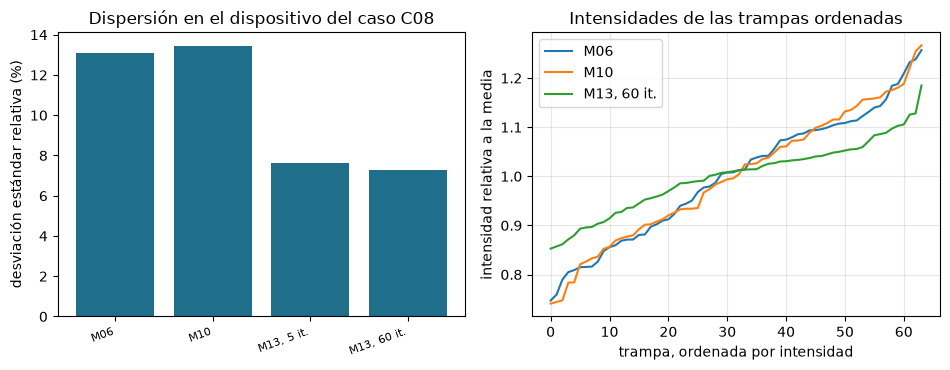

In [9]:
# desviación estándar relativa en el dispositivo de cada holograma, y las intensidades ordenadas de tres de
# ellos
fig, (a, b) = plt.subplots(1, 2, figsize=(9.6, 3.8))
names = list(on_device)
a.bar(range(len(names)), [on_device[k]["rel_std_pct"] for k in names], color="#1f6f8b")
a.set_xticks(range(len(names)))
a.set_xticklabels(names, rotation=20, ha="right", fontsize=8)
a.set_ylabel("desviación estándar relativa (%)")
a.set_title("Dispersión en el dispositivo del caso C08")
for name in ("M06", "M10", "M13, 60 it."):
    b.plot(np.sort(on_device[name]["trap_intensity"]), label=name)
b.set_xlabel("trampa, ordenada por intensidad")
b.set_ylabel("intensidad relativa a la media")
b.set_title("Intensidades de las trampas ordenadas")
b.legend()
b.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

M10 y M06 están al mismo nivel, 13,45 y 13,07 por ciento, y las dos barras de M13 están en 7,65 y 7,27 por ciento: con el dispositivo en su modelo el gradiente conjugado quita 46 por ciento de la dispersión que deja M10, con una uniformidad de 0,8370 frente a 0,7380. En las curvas ordenadas las trampas de M13 quedan entre cerca de 0,85 y 1,18 de la media, frente a cerca de 0,74 y 1,27 para M06 y M10, y su centro es más plano. Cuesta poca luz: la eficiencia es 0,6824 frente a 0,6851, una pérdida de 0,0027. La figura es para un inicio, una semilla y un dispositivo; el disco del artículo es otro problema, y el notebook no lo repite.

La última figura muestra dónde movió el holograma el optimizador que conoce la diafonía: la diferencia envuelta, píxel a píxel, entre el patrón de fase de M13 y el patrón de GS ponderado del que partió.

cambio rms 0.0778 rad | mayor 0.357 rad
fracción de píxeles sobre 0.1 rad: 0.190


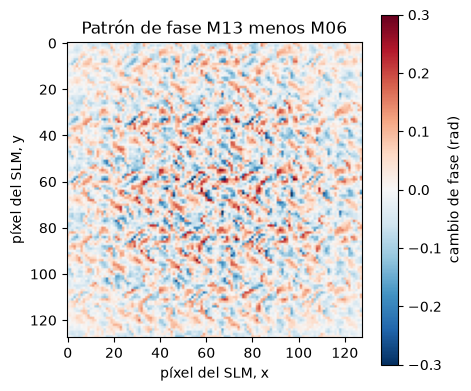

In [10]:
# lo que cambió M13 en el holograma: la diferencia de fase envuelta entre los patrones de M13 y de M06
change = np.angle(np.exp(1j * (res13b.phi - res06.phi)))
print(f"cambio rms {np.sqrt(np.mean(change ** 2)):.4f} rad | mayor {np.abs(change).max():.3f} rad")
print(f"fracción de píxeles sobre 0.1 rad: {np.mean(np.abs(change) > 0.1):.3f}")
fig, ax = plt.subplots(figsize=(4.8, 4.2))
image = ax.imshow(change, cmap="RdBu_r", vmin=-0.3, vmax=0.3)
fig.colorbar(image, ax=ax, label="cambio de fase (rad)")
ax.set_xlabel("píxel del SLM, x")
ax.set_ylabel("píxel del SLM, y")
ax.set_title("Patrón de fase M13 menos M06")
plt.tight_layout()
plt.show()

El cambio es pequeño y se reparte por toda la apertura: el rms es 0,0778 rad y el mayor cambio 0,357 rad, y 19,0 por ciento de los píxeles se mueve más de 0,1 rad. En una escala de más y menos 0,3 rad la figura muestra un patrón fino de signo alternado a la escala de unos pocos píxeles, más fuerte en el centro de la apertura, donde el haz lleva más luz, y más tenue hacia los bordes. Esa es toda la diferencia entre un holograma que muestra 13,07 por ciento de dispersión en el dispositivo y uno que muestra 7,27 por ciento: una predistorsión de unas centésimas de radián por píxel, a la escala que difumina el núcleo de diafonía, que un gráfico de los patrones mismos no podría revelar.

## Resultados

**Respuesta:** Un optimizador de gradiente conjugado con el núcleo de diafonía en su modelo recupera parte de lo que cuesta la diafonía, y el mismo optimizador sobre el modelo ideal no recupera nada. Desde el mismo inicio de GS ponderado, en el dispositivo del caso C08, M10 termina con una desviación estándar relativa de 13,45 por ciento frente a 13,07 del inicio, mientras M13 llega a 7,65 por ciento en 5 iteraciones y a 7,27 por ciento en 60, con una uniformidad de 0,8370 (0,7380 para M10), quitando 46 por ciento de la dispersión que deja M10 a cambio de 0,0027 de la luz (una eficiencia de 0,6824 frente a 0,6851). Sin dispositivo en su modelo es igual a M10 hasta 0,00e+00 rad. Cerca de la mitad del piso que deja viene del cuantizador y el parpadeo: el mismo optimizador corrido para el dispositivo continuo llega a 3,55 por ciento ahí, de modo que 3,55 por ciento queda solo con la diafonía y la apertura, y muestra 6,63 por ciento en el dispositivo completo, menos que el 7,27 de la corrida con el modelo completo, así que el cuantizador de paso directo en el modelo no rinde en este caso.

Lo que el notebook no muestra es el disco grande del artículo, un inicio aleatorio (el registro del método, `docs/design/methods/M13-crosstalk-aware-cg.md`, lo mide mucho peor, 57,3 por ciento tras 12 iteraciones, y no halla una ganancia sistemática en el dispositivo cuantizado sobre tres semillas), por qué cuesta el cuantizador de paso directo, ni una implementación independiente de M13, que no existe entre las dependencias.

## Resumen

- M13 es M10 corrido sobre el campo focal del dispositivo: núcleo de diafonía, apertura del píxel y un cuantizador de paso directo, con el adjunto del núcleo en forma cerrada.
- En el dispositivo de C08 baja la dispersión de 13,45 por ciento (M10) a 7,27 por ciento en 60 iteraciones, a cambio de 0,0027 de la luz, y la mayor parte de la ganancia llega en sus primeras 5 iteraciones.
- Cerca de 3 de los 6,6 puntos del piso son el cuantizador y el parpadeo; dejar el cuantizador fuera del modelo funciona mejor en el dispositivo completo aquí (6,63 por ciento).
- Sin dispositivo es exactamente igual a M10.
- No existe una implementación de referencia fijada de M13 entre las dependencias.

## Referencias

- Schroff et al. (2023). Accurate holographic light potentials using pixel crosstalk modelling. Scientific Reports 13, 3252. https://doi.org/10.1038/s41598-023-30296-6
- Harte et al. (2014). A conjugate gradient minimisation approach to generating holographic traps for ultracold atoms. Optics Express 22, 26548. https://doi.org/10.1364/OE.22.026548